# STEP 7. Auxiliary question 2 — which characteristics are related to a net-decline transition?

> **Auxiliary question 2**: Which characteristics, such as sales, foot traffic and store density, are related to a net-decline transition in the next quarter?

If STEP 6 looked at just one thing, **"Korean restaurants or not"**, here we put **many characteristics in at once** and read each one's contribution.

## Two things are done here

| | Sample | Purpose |
|---|---|---|
| **7-1 Doubly robust estimation** | Matched sample (`06_matched.pkl`) | Put a regression on top of the matching to re-check the ATT |
| **7-3 to 7-6 Explanatory model** | Neighborhood commercial areas, **training quarters only** | The main part of auxiliary question 2 |

## Why doubly robust

Matching equalizes the conditions, and on top of that a regression corrects the residual imbalance once more. **The estimate holds up if either one is wrong**: if the propensity score model is wrong but the outcome model is right, and the other way around.

## Preventing leakage

The explanatory model uses **only `config.TRAIN_QUARTERS` (20231-20253)**. The variable selection and functional-form decisions made here are passed on to the STEP 8 prediction model, and if they were decided by looking at the validation quarter (20254), the validation would be meaningless.

Required package: `statsmodels` (needed for cluster-robust standard errors)

In [1]:
import sys, os
from pathlib import Path

# Find the project root wherever the notebook is opened and add it to sys.path
ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

# If the kernel is not restarted after editing config.py, Python keeps the old module cached.
# The two lines below force that cache to refresh.
import importlib
if "config" in sys.modules:
    importlib.reload(sys.modules["config"])

import numpy as np
import pandas as pd
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
print("Project root:", ROOT.name)

import warnings
# Malgun Gothic has no U+2212 (minus sign), so every figure raises a warning. Leave the figures as they are and silence only the warning.
warnings.filterwarnings("ignore", message=r"Glyph 8722 .* missing from font")

Project root: seoul-closure-risk


In [2]:
import matplotlib.pyplot as plt
import statsmodels.api as sm
from config import (dummies, PROC, FIG, TARGET_TYPE, COVARIATES, TRAIN_QUARTERS,
                    VALID_Q, SCORE_Q, set_plot_style)
set_plot_style()
OUT = FIG.parent
REF_SVC = "Korean restaurants"        # reference category for the service category dummies; every coefficient is read 'relative to Korean restaurants'

def fit_logit(frame, X, label=""):
    """Logistic regression with cluster-robust (commercial area) standard errors. Returns coefficients, odds ratios and average marginal effects (AME) together"""
    X = sm.add_constant(X.astype(float), has_constant="add")
    m = sm.Logit(frame["y"].astype(int).values, X.values).fit(
        disp=0, cov_type="cluster", cov_kwds={"groups": frame["area_code"].values})
    p = m.predict(X.values)
    scale = (p * (1 - p)).mean()          # scale of the logistic average marginal effect
    res = pd.DataFrame({
        "coef": m.params, "std_error": m.bse, "z": m.tvalues, "p_value": m.pvalues,
        "odds_ratio": np.exp(m.params), "AME(%p)": m.params * scale * 100,
    }, index=X.columns)
    res.attrs["model"] = m
    res.attrs["label"] = label
    return res, m

matched = pd.read_pickle(PROC / "06_matched.pkl")
panel   = pd.read_pickle(PROC / "03_panel.pkl")
print(f"Matched sample {matched.shape} | full panel {panel.shape}")

Matched sample (14086, 40) | full panel (67475, 34)


## 7-1. Doubly robust estimation

On the matched sample, fit `y ~ treated + covariates + quarter dummies`. The `treated` coefficient is the effect after correcting even the residual imbalance.

The ATT is computed again by **g-computation**: set every row to treated and to control, predict the probability each way, and average the difference. This is the standard way to move a coefficient to the probability scale.

In [3]:
X = pd.concat([
    matched[["treated"]],
    matched[COVARIATES],
    pd.get_dummies(matched["quarter_code"], prefix="q", drop_first=True),
], axis=1)

dr, m_dr = fit_logit(matched, X, "doubly robust")
display(dr.loc[["treated"] + COVARIATES].round(4))

Xc = sm.add_constant(X.astype(float), has_constant="add")
X1 = Xc.copy(); X1["treated"] = 1.0
X0 = Xc.copy(); X0["treated"] = 0.0
att_dr = (m_dr.predict(X1.values) - m_dr.predict(X0.values)).mean()

pairs = matched.sort_values(["pair_id", "role"])
y1 = pairs[pairs["role"] == "treated"].sort_values("pair_id")["y"].to_numpy()
y0 = pairs[pairs["role"] == "control"].sort_values("pair_id")["y"].to_numpy()
att_match = (y1 - y0).mean()

print(f"ATT from matching alone   {(att_match)*100:+.2f} pp   (STEP 6)")
print(f"Doubly robust ATT       {(att_dr)*100:+.2f} pp   (matching + regression adjustment)")
print(f"Difference               {(att_dr-att_match)*100:+.2f} pp")
print("\nNote: if the two values are close, the matching already balanced the conditions well.")
print("   If they differ a lot, residual imbalance remained, so use the regression-adjusted value.")

,coef,std_error,z,p_value,odds_ratio,AME(%p)
treated,-0.3273,0.0394,-8.3127,0.0000,0.7209,-5.9925
log_store_count,0.6682,0.0416,16.0773,0.0000,1.9507,12.2328
log_foot_traffic,0.0160,0.0264,0.6046,0.5454,1.0161,0.2927
log_area_size,-0.0020,0.0442,-0.0457,0.9636,0.9980,-0.0369
log_attracting_facilities,0.0087,0.0347,0.2519,0.8012,1.0088,0.1599


ATT from matching alone   -5.57 pp   (STEP 6)
Doubly robust ATT       -6.00 pp   (matching + regression adjustment)
Difference               -0.43 pp

Note: if the two values are close, the matching already balanced the conditions well.
   If they differ a lot, residual imbalance remained, so use the regression-adjusted value.


## 7-2. What the control group actually is

The ATT is called "Korean restaurants vs other food-service", but to interpret it correctly we need to look at **the actual composition of the control group the matching picked**. When matching on size and foot traffic, certain service categories can end up over-represented.

In [4]:
ctrl = matched[matched["role"] == "control"]
comp = (ctrl["service_name"].value_counts(normalize=True)
        .rename("matched_control_share").to_frame())
pool = (panel[(panel["area_type"] == TARGET_TYPE) &
              (panel["service_name"] != REF_SVC)]["service_name"]
        .value_counts(normalize=True).rename("neighborhood_control_pool_share"))
comp = comp.join(pool)
comp["over_under_ratio"] = comp["matched_control_share"] / comp["neighborhood_control_pool_share"]
display(comp.round(3))
print(f"-> The ATT is effectively a comparison of '{REF_SVC} vs "
      f"a control group centered on {comp.index[0]} and {comp.index[1]}'.")
print("   When reporting, do not lump it together as 'all other food-service'.")

,matched_control_share,neighborhood_control_pool_share,over_under_ratio
service_name,,,
Coffee and beverages,0.527,0.314,1.681
Beer and casual pubs,0.214,0.186,1.151
Korean snack-food restaurants,0.076,0.147,0.519
Western restaurants,0.075,0.060,1.252
Chinese restaurants,0.028,0.049,0.566
Bakeries,0.025,0.066,0.381
Fried-chicken shops,0.020,0.078,0.257
Japanese restaurants,0.020,0.042,0.470
Fast-food restaurants,0.015,0.058,0.251


-> The ATT is effectively a comparison of 'Korean restaurants vs a control group centered on Coffee and beverages and Beer and casual pubs'.
   When reporting, do not lump it together as 'all other food-service'.


## 7-3. Explanatory model: sample and variables

- Sample: **neighborhood commercial areas, training quarters (20231-20253)**
- Reference categories: `Korean restaurants` for service category, the first category for district and for quarter
- `store_density` is not included: `log(density) = log(store_count) - log(area)` is already a linear combination of two variables that are in the model
- `franchise_share` was non-monotonic (peaking at Q2) in STEP 4, so it enters as **band dummies**

In [5]:
gm = panel[(panel["area_type"] == TARGET_TYPE) &
           (panel["quarter_code"].isin(TRAIN_QUARTERS))].copy()
assert VALID_Q not in gm["quarter_code"].unique(), "The validation quarter got mixed in"
assert SCORE_Q not in gm["quarter_code"].unique()

gm["franchise_band"] = pd.cut(gm["franchise_share"], [-0.001, 0, 0.2, 0.5, 1.001],
                            labels=["0%", "0~20%", "20~50%", "50%+"])

print(f"Explanatory model sample {len(gm):,} rows | quarters {gm['quarter_code'].min()}~{gm['quarter_code'].max()}")
print(f"{gm['area_code'].nunique()} commercial areas | positive rate {gm['y'].mean():.1%}\n")
display(gm.groupby("franchise_band", observed=True)
        .agg(n_cells=("y", "size"), net_decline_rate=("y", "mean")).round(3))

Explanatory model sample 31,875 rows | quarters 20231~20253
925 commercial areas | positive rate 23.6%



,n_cells,net_decline_rate
franchise_band,,
0%,9449,0.205
0~20%,13610,0.262
20~50%,6325,0.236
50%+,2491,0.211


### Building up the model in stages

Putting everything in at once makes it impossible to tell which variable explains what. We add them one at a time and see how the coefficients change.

| Model | What goes in |
|---|---|
| A | 4 covariates + quarter |
| B | A + commercial-area characteristics (food-service share, franchise band) |
| C | B + service category dummies |
| D | C + district fixed effects |

In [6]:
def design(frame, svc=False, gu=False, extra=False):
    parts = [frame[COVARIATES]]
    if extra:
        parts.append(frame[["food_service_share"]])
        parts.append(pd.get_dummies(frame["franchise_band"], prefix="fr", drop_first=True))
    if svc:
        dum = dummies(frame["service_name"], prefix="svc")
        parts.append(dum.drop(columns=[f"svc_{REF_SVC}"]))
    if gu:
        parts.append(dummies(frame["district"], prefix="gu", drop_first=True))
    parts.append(pd.get_dummies(frame["quarter_code"], prefix="q", drop_first=True))
    return pd.concat(parts, axis=1)

models = {}
specs = [("A baseline",       dict()),
         ("B +area characteristics",  dict(extra=True)),
         ("C +service category",      dict(extra=True, svc=True)),
         ("D +district",    dict(extra=True, svc=True, gu=True))]
for nm, kw in specs:
    models[nm] = fit_logit(gm, design(gm, **kw), nm)

summary = pd.DataFrame([{
    "model_name": nm, "n_features": len(r) - 1, "pseudo R²": m.prsquared,
    "AIC": m.aic, "log_store_count_coef": r.loc["log_store_count", "coef"],
} for nm, (r, m) in models.items()])
display(summary.round(4))
print("Note: if the log_store_count coefficient barely changes as the model grows, that effect is not explained away by other variables.")

,model_name,n_features,pseudo R²,AIC,log_store_count_coef
0,A baseline,14,0.0291,33855.2666,0.5700
1,B +area characteristics,18,0.0297,33843.8979,0.6065
2,C +service category,27,0.0333,33735.2845,0.8077
3,D +district,51,0.0349,33727.4638,0.8246


Note: if the log_store_count coefficient barely changes as the model grows, that effect is not explained away by other variables.


## 7-4. Final model coefficients

**AME (average marginal effect)** is the coefficient moved to the probability scale. It reads directly as "how many percentage points (pp) does the net-decline probability change when this variable rises by 1 unit". It is more intuitive to interpret than the odds ratio.

Standard errors are computed **clustered by commercial area**: the same commercial area is observed repeatedly for up to 11 quarters, so ordinary standard errors would be underestimated.

In [7]:
res, m_final = models["D +district"]
show = [c for c in res.index if not c.startswith(("gu_", "q_"))]
tbl = res.loc[show].copy()
tbl["significant"] = pd.cut(tbl["p_value"], [0, .001, .01, .05, 1], labels=["***", "**", "*", ""])
display(tbl.round(4))
print(f"n = {int(m_final.nobs):,} | {gm['area_code'].nunique()} commercial-area clusters | "
      f"pseudo R² = {m_final.prsquared:.4f}")
print(f"{sum(c.startswith('gu_') for c in res.index)} district dummies, "
      f"{sum(c.startswith('q_') for c in res.index)} quarter dummies omitted")

# Sort by size; the visualization and save cells below use effects.
# Keep it in the same cell that builds the table so both are created together even if cells run out of order.
effects = (tbl[tbl.index != "const"]
           .assign(abs_ame=lambda x: x["AME(%p)"].abs())
           .sort_values("abs_ame", ascending=False)[["AME(%p)", "p_value", "significant"]])
print()
print("[Sorted by size: what is most strongly related]")
display(effects.round(4))

,coef,std_error,z,p_value,odds_ratio,AME(%p),significant
const,-2.7751,0.3581,-7.7491,0.0000,0.0623,-48.0575,***
log_store_count,0.8246,0.0302,27.3149,0.0000,2.2810,14.2803,***
log_foot_traffic,0.0416,0.0236,1.7646,0.0776,1.0425,0.7204,
log_area_size,-0.0800,0.0372,-2.1505,0.0315,0.9231,-1.3853,*
log_attracting_facilities,-0.0717,0.0277,-2.5856,0.0097,0.9308,-1.2423,**
food_service_share,-0.7992,0.1754,-4.5573,0.0000,0.4497,-13.8395,***
fr_0~20%,-0.0602,0.0355,-1.6950,0.0901,0.9416,-1.0427,
fr_20~50%,-0.0039,0.0431,-0.0896,0.9286,0.9961,-0.0669,
fr_50%+,-0.0612,0.0791,-0.7741,0.4389,0.9406,-1.0600,
svc_Korean snack-food restaurants,0.5351,0.0603,8.8742,0.0000,1.7076,9.2662,***


n = 31,875 | 925 commercial-area clusters | pseudo R² = 0.0349
24 district dummies, 10 quarter dummies omitted

[Sorted by size: what is most strongly related]


,AME(%p),p_value,significant
log_store_count,14.2803,0.0000,***
svc_Fast-food restaurants,13.8863,0.0000,***
food_service_share,-13.8395,0.0000,***
svc_Fried-chicken shops,10.5637,0.0000,***
svc_Japanese restaurants,10.0495,0.0000,***
svc_Bakeries,9.5367,0.0000,***
svc_Korean snack-food restaurants,9.2662,0.0000,***
svc_Western restaurants,8.0184,0.0000,***
svc_Beer and casual pubs,6.9543,0.0000,***
svc_Coffee and beverages,6.4412,0.0000,***


## 7-5. Service category effects: compared with the PSM result

All service category dummies are **relative to Korean restaurants**. With covariates adjusted for, a category riskier than Korean restaurants is (+) and a safer one is (-).

The STEP 6 ATT (-5.8 pp) said "Korean restaurants are 5.8 pp safer than other service categories under the same conditions". **If the service category dummies mostly come out (+) here, the two methods have reached the same conclusion.**

In [8]:
svc_rows = [c for c in res.index if c.startswith("svc_")]
sv = res.loc[svc_rows, ["coef", "odds_ratio", "AME(%p)", "p_value"]].copy()
sv.index = [c.replace("svc_", "") for c in sv.index]
sv = sv.sort_values("AME(%p)", ascending=False)
display(sv.round(4))
print(f"Reference category: {REF_SVC} (AME 0)")
print(f"{(sv['AME(%p)'] > 0).sum()} service categories riskier than Korean restaurants / "
      f"{(sv['AME(%p)'] < 0).sum()} safer")
print(f"\nSTEP 6 ATT (Korean restaurants - control) : {(att_match)*100:+.2f} pp")
print(f"Explanatory model, mean service dummy : {(-sv['AME(%p)'].mean()/100)*100:+.2f} pp  (sign flipped to match)")
print("-> If the two methods point the same way, the conclusion does not depend on the method.")

,coef,odds_ratio,AME(%p),p_value
Fast-food restaurants,0.8019,2.2297,13.8863,0.0000
Fried-chicken shops,0.6100,1.8405,10.5637,0.0000
Japanese restaurants,0.5803,1.7866,10.0495,0.0000
Bakeries,0.5507,1.7345,9.5367,0.0000
Korean snack-food restaurants,0.5351,1.7076,9.2662,0.0000
Western restaurants,0.4630,1.5889,8.0184,0.0000
Beer and casual pubs,0.4016,1.4942,6.9543,0.0000
Coffee and beverages,0.3720,1.4506,6.4412,0.0000
Chinese restaurants,0.3385,1.4029,5.8622,0.0001


Reference category: Korean restaurants (AME 0)


9 service categories riskier than Korean restaurants / 0 safer

STEP 6 ATT (Korean restaurants - control) : -5.57 pp
Explanatory model, mean service dummy : -8.95 pp  (sign flipped to match)
-> If the two methods point the same way, the conclusion does not depend on the method.


## 7-6. Sales: observed sub-sample

Sales are blank for cells with 2 or fewer stores because they are de-identified, and even within the analysis sample the observation rate differs by service category. So we **leave it out of the main model and look at it separately here**.

Sales are also an *outcome* of the service category (Korean restaurants and cafes have different business models), so the coefficient must not be read causally. Read it only as **the association "cells with low sales turned out to be riskier"**.

In [9]:
sub = gm[gm["sales_observed"]].copy()
sub["log_sales"]     = np.log1p(sub["monthly_sales"])
sub["log_sales_per_store"] = np.log1p(sub["sales_per_store"])
print(f"Sales-observed sample {len(sub):,} / {len(gm):,} ({len(sub)/len(gm):.1%})\n")

Xs = pd.concat([design(sub, extra=True, svc=True, gu=True),
                sub[["log_sales_per_store"]]], axis=1)
res_s, m_s = fit_logit(sub, Xs, "with sales")
show_s = [c for c in res_s.index if not c.startswith(("gu_", "q_", "svc_"))]
display(res_s.loc[show_s].round(4))
print(f"pseudo R²  without sales {m_final.prsquared:.4f} -> with sales {m_s.prsquared:.4f}")
print("Note: if adding sales_per_store barely raises explanatory power, the size variables already carry that information.")

Sales-observed sample 28,976 / 31,875 (90.9%)



,coef,std_error,z,p_value,odds_ratio,AME(%p)
const,0.0117,0.4492,0.0260,0.9793,1.0117,0.2020
log_store_count,0.8999,0.0317,28.4034,0.0000,2.4594,15.5837
log_foot_traffic,0.0432,0.0250,1.7295,0.0837,1.0441,0.7478
log_area_size,-0.1458,0.0381,-3.8243,0.0001,0.8644,-2.5241
log_attracting_facilities,-0.0565,0.0286,-1.9747,0.0483,0.9451,-0.9776
food_service_share,-0.6905,0.1743,-3.9619,0.0001,0.5013,-11.9573
fr_0~20%,-0.0401,0.0381,-1.0520,0.2928,0.9607,-0.6945
fr_20~50%,0.0725,0.0464,1.5609,0.1186,1.0752,1.2551
fr_50%+,0.0326,0.0924,0.3526,0.7244,1.0331,0.5640
log_sales_per_store,-0.1266,0.0146,-8.7003,0.0000,0.8811,-2.1922


pseudo R²  without sales 0.0349 -> with sales 0.0404
Note: if adding sales_per_store barely raises explanatory power, the size variables already carry that information.


## 7-7. Visualization

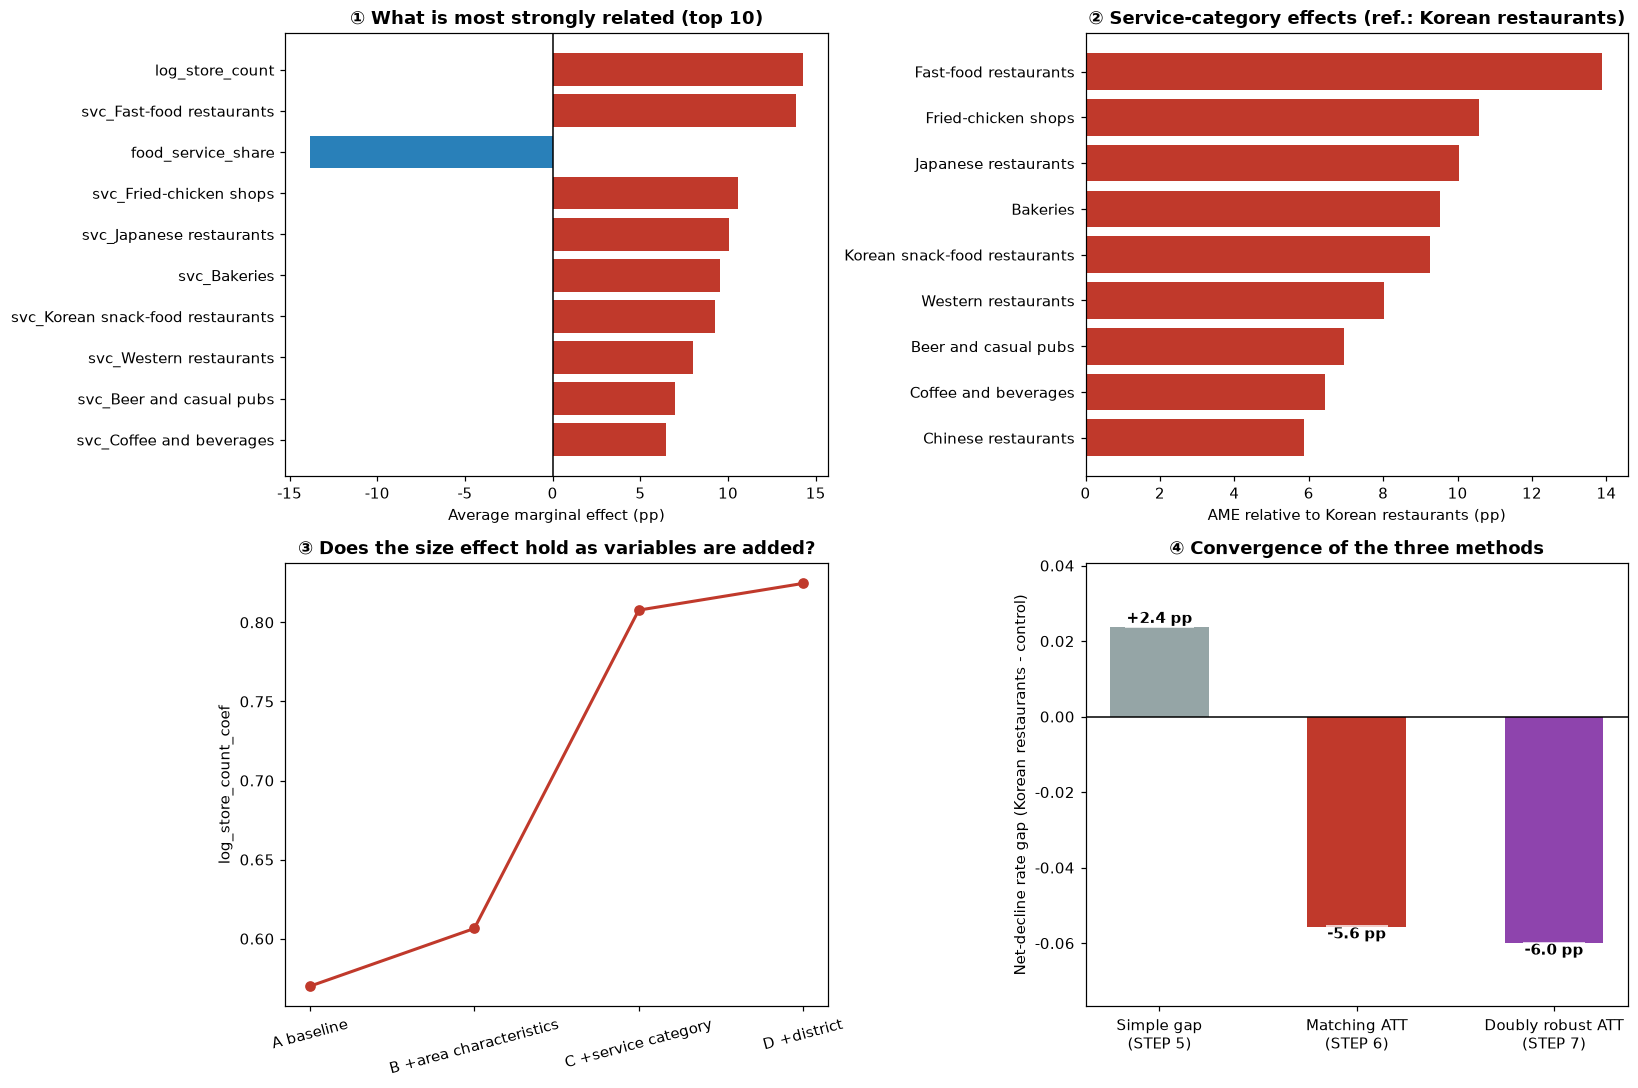

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))

# ① AME by size
top = effects.head(10).iloc[::-1]
cols = ["#c0392b" if v > 0 else "#2980b9" for v in top["AME(%p)"]]
ax[0,0].barh(top.index, top["AME(%p)"], color=cols)
ax[0,0].axvline(0, c="k", lw=1)
ax[0,0].set_xlabel("Average marginal effect (pp)")
ax[0,0].set_title("① What is most strongly related (top 10)", weight="bold")

# ② Service category dummies
sv2 = sv.sort_values("AME(%p)")
ax[0,1].barh(sv2.index, sv2["AME(%p)"],
             color=["#c0392b" if v > 0 else "#2980b9" for v in sv2["AME(%p)"]])
ax[0,1].axvline(0, c="k", lw=1)
ax[0,1].set_xlabel(f"AME relative to {REF_SVC} (pp)")
ax[0,1].set_title(f"② Service-category effects (ref.: {REF_SVC})", weight="bold")

# ③ log_store_count coefficient by model stage
ax[1,0].plot(summary["model_name"], summary["log_store_count_coef"], marker="o", color="#c0392b", lw=2)
ax[1,0].set_ylabel("log_store_count_coef"); ax[1,0].tick_params(axis="x", rotation=15)
ax[1,0].set_title("③ Does the size effect hold as variables are added?", weight="bold")

# ④ Matching ATT vs doubly robust
labels = ["Simple gap\n(STEP 5)", "Matching ATT\n(STEP 6)", "Doubly robust ATT\n(STEP 7)"]
gap0 = (panel[(panel["area_type"]==TARGET_TYPE)].pipe(
    lambda f: f.loc[f["service_name"]==REF_SVC, "y"].mean()
              - f.loc[f["service_name"]!=REF_SVC, "y"].mean()))
vals = [gap0, att_match, att_dr]
bars = ax[1,1].bar(labels, vals, width=.5,
                   color=["#95a5a6", "#c0392b", "#8e44ad"])
ax[1,1].axhline(0, c="k", lw=1)
ax[1,1].margins(y=0.20)
for b, v in zip(bars, vals):
    ax[1,1].text(b.get_x()+b.get_width()/2, v, f"{(v)*100:+.1f} pp", ha="center",
                 va="bottom" if v > 0 else "top", weight="bold",
                 bbox=dict(fc="white", ec="none", alpha=.75, pad=1))
ax[1,1].set_ylabel("Net-decline rate gap (Korean restaurants - control)")
ax[1,1].set_title("④ Convergence of the three methods", weight="bold")

plt.tight_layout()
plt.savefig(FIG / "step7_explain.png", dpi=130)
plt.show()

## 7-8. Saving and wrap-up

In [11]:
effects.to_csv(OUT / "q2_effects.csv", encoding="utf-8-sig")
sv.to_csv(OUT / "q2_service_effects.csv", encoding="utf-8-sig")

# Save the doubly robust ATT to a file. The STEP 9 summary reads this value,
# so if it is not saved here, downstream documents would print the old number as is.
pd.DataFrame([{"doubly_robust_att": att_dr}]).to_csv(
    OUT / "h2_att_dr.csv", index=False, encoding="utf-8-sig")

print("[saved] outputs/q2_effects.csv, q2_service_effects.csv, h2_att_dr.csv")
print("[saved] figures/step7_explain.png\n")

print("-- Summary of the answer to auxiliary question 2 --")
for i, (nm, row) in enumerate(effects.head(5).iterrows(), 1):
    d_ = "riskier as it rises" if row["AME(%p)"] > 0 else "safer as it rises"
    print(f"  {i}. {nm:16} {row['AME(%p)']:+7.2f}%p  {d_} {row['significant']}")
print()
print("-- To hand over to STEP 8 --")
print(f"  Training quarters: {TRAIN_QUARTERS[0]} ~ {TRAIN_QUARTERS[-1]} (confirmed validation {VALID_Q} is excluded)")
print(f"  Baseline pseudo R²: {m_final.prsquared:.4f}; a prediction model is only meaningful if it beats this")
print("  Variable form decisions: franchise as band dummies, store_density excluded (collinearity)")

[saved] outputs/q2_effects.csv, q2_service_effects.csv, h2_att_dr.csv
[saved] figures/step7_explain.png

-- Summary of the answer to auxiliary question 2 --
  1. log_store_count   +14.28%p  riskier as it rises ***
  2. svc_Fast-food restaurants  +13.89%p  riskier as it rises ***
  3. food_service_share  -13.84%p  safer as it rises ***
  4. svc_Fried-chicken shops  +10.56%p  riskier as it rises ***
  5. svc_Japanese restaurants  +10.05%p  riskier as it rises ***

-- To hand over to STEP 8 --
  Training quarters: 20231 ~ 20253 (confirmed validation 20254 is excluded)
  Baseline pseudo R²: 0.0349; a prediction model is only meaningful if it beats this
  Variable form decisions: franchise as band dummies, store_density excluded (collinearity)


---

## What to do in STEP 8 (prediction)

- Train on `TRAIN_QUARTERS` (20231-20253) -> validate on `VALID_Q` (20254, target 20261)
- Baseline order: majority class -> previous-quarter state -> logistic -> tree/boosting
- Evaluate with **AUC, PR-AUC, Brier**. With a 25% positive rate, accuracy is meaningless
- Check probability calibration: to rank service categories by district, the probability values themselves must be trustworthy
- Check the variation in performance across quarters with rolling-origin validation